In [1]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
    roc_curve
)

import joblib

pd.set_option("display.max_columns", None)


## 1. Load Dataset

In [2]:
# Load the dataset

df = pd.read_csv("diabetes_prediction_dataset.csv")

print("Dataset shape:", df.shape)
display(df.head())


Dataset shape: (100000, 9)


,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


## 2. Understand the Dataset

In [3]:
# Basic information

print("Columns:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
display(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nTarget distribution:")
display(df["diabetes"].value_counts())

print("\nTarget percentage:")
display(df["diabetes"].value_counts(normalize=True).mul(100).round(2))


Columns:
['gender', 'age', 'hypertension', 'heart_disease', 'smoking_history', 'bmi', 'HbA1c_level', 'blood_glucose_level', 'diabetes']

Data types:
gender                  object
age                    float64
hypertension             int64
heart_disease            int64
smoking_history         object
bmi                    float64
HbA1c_level            float64
blood_glucose_level      int64
diabetes                 int64
dtype: object

Missing values:


gender                 0
age                    0
hypertension           0
heart_disease          0
smoking_history        0
bmi                    0
HbA1c_level            0
blood_glucose_level    0
diabetes               0
dtype: int64


Duplicate rows: 3854

Target distribution:


diabetes
0    91500
1     8500
Name: count, dtype: int64


Target percentage:


diabetes
0    91.5
1     8.5
Name: proportion, dtype: float64

## 3. Data Cleaning

In [4]:
# Remove duplicate rows

df = df.drop_duplicates().reset_index(drop=True)

# Replace common missing-value symbols if they exist
df = df.replace(["?", "NA", "N/A", "null", "None"], np.nan)

print("Shape after removing duplicates:", df.shape)
display(df.isnull().sum())


Shape after removing duplicates: (96146, 9)


gender                 0
age                    0
hypertension           0
heart_disease          0
smoking_history        0
bmi                    0
HbA1c_level            0
blood_glucose_level    0
diabetes               0
dtype: int64

## 4. Exploratory Data Analysis (EDA)

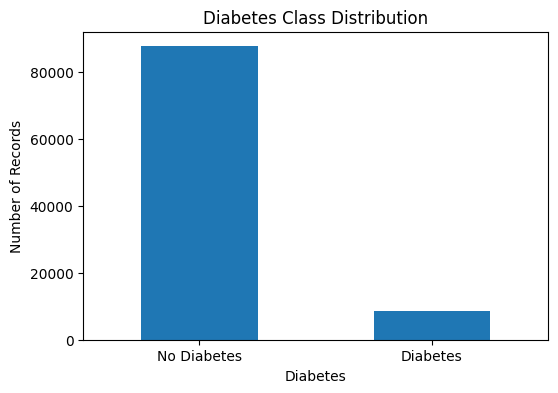

In [5]:
# Target distribution

plt.figure(figsize=(6, 4))
df["diabetes"].value_counts().sort_index().plot(kind="bar")
plt.title("Diabetes Class Distribution")
plt.xlabel("Diabetes")
plt.ylabel("Number of Records")
plt.xticks([0, 1], ["No Diabetes", "Diabetes"], rotation=0)
plt.show()


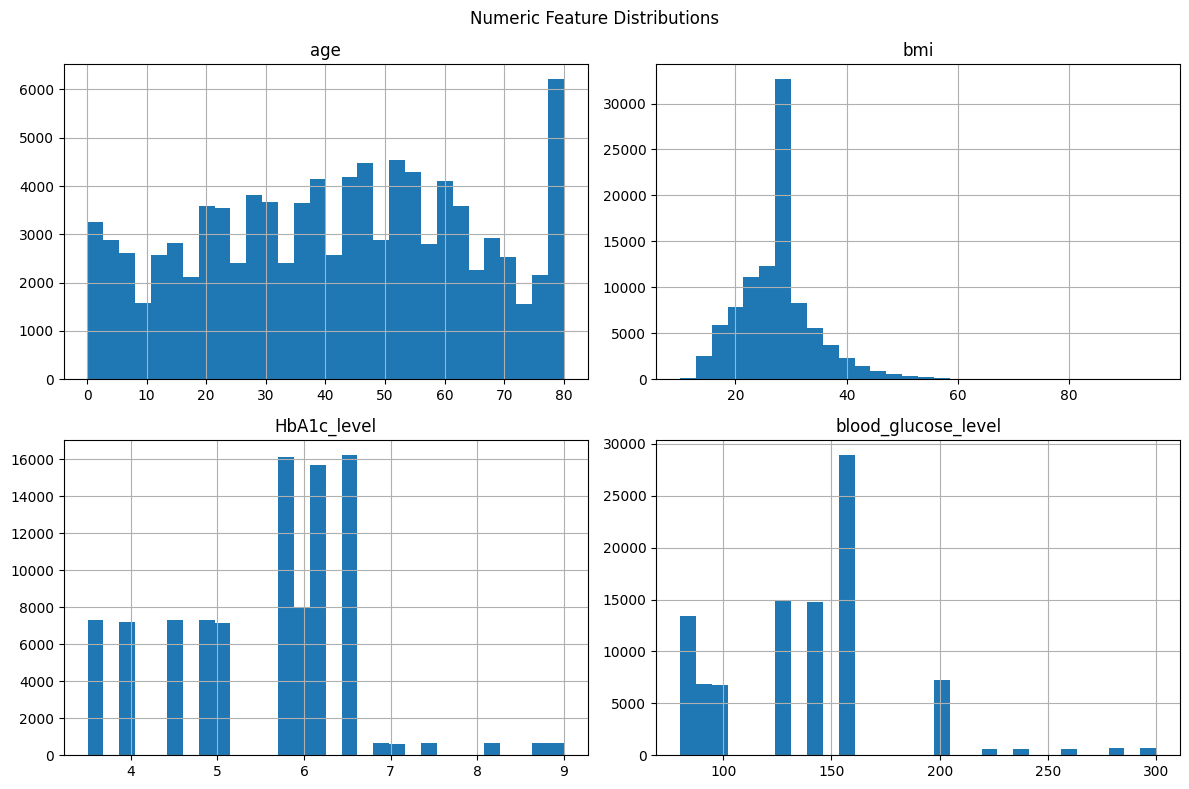

In [6]:
# Numeric feature distributions

numeric_cols = [
    "age",
    "bmi",
    "HbA1c_level",
    "blood_glucose_level"
]

df[numeric_cols].hist(figsize=(12, 8), bins=30)
plt.suptitle("Numeric Feature Distributions")
plt.tight_layout()
plt.show()


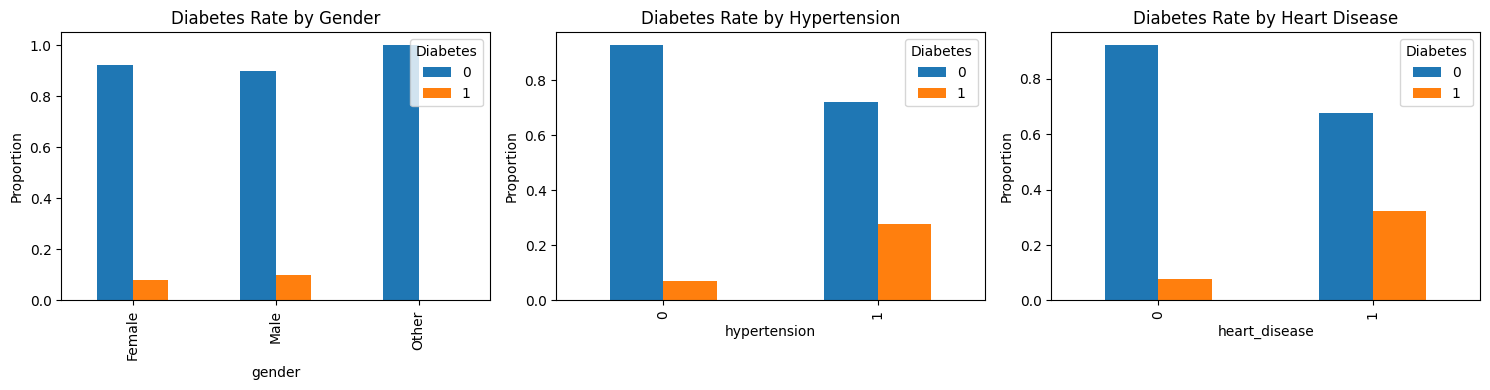

In [7]:
# Diabetes rate by selected categorical/boolean features

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

pd.crosstab(df["gender"], df["diabetes"], normalize="index").plot(
    kind="bar", ax=axes[0]
)
axes[0].set_title("Diabetes Rate by Gender")
axes[0].set_ylabel("Proportion")
axes[0].legend(title="Diabetes")

pd.crosstab(df["hypertension"], df["diabetes"], normalize="index").plot(
    kind="bar", ax=axes[1]
)
axes[1].set_title("Diabetes Rate by Hypertension")
axes[1].set_ylabel("Proportion")
axes[1].legend(title="Diabetes")

pd.crosstab(df["heart_disease"], df["diabetes"], normalize="index").plot(
    kind="bar", ax=axes[2]
)
axes[2].set_title("Diabetes Rate by Heart Disease")
axes[2].set_ylabel("Proportion")
axes[2].legend(title="Diabetes")

plt.tight_layout()
plt.show()


## 5. Prepare Features and Target

In [8]:
# Separate input features (X) and target (y)

X = df.drop(columns=["diabetes"])
y = df["diabetes"]

print("X shape:", X.shape)
print("y shape:", y.shape)

# Identify numeric and categorical columns
numeric_features = X.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_features = X.select_dtypes(include=["object", "category"]).columns.tolist()

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)


X shape: (96146, 8)
y shape: (96146,)
Numeric features: ['age', 'hypertension', 'heart_disease', 'bmi', 'HbA1c_level', 'blood_glucose_level']
Categorical features: ['gender', 'smoking_history']


## 6. Train-Test Split

In [9]:
# Split data into training and testing sets
# stratify=y keeps the class ratio similar in both sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)


Training data: (76916, 8)
Testing data: (19230, 8)


## 7. Preprocessing Pipeline

In [10]:
# Numeric preprocessing:
# - Fill missing numeric values with the median
# - Standardize numeric values

numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

# Categorical preprocessing:
# - Fill missing categories with the most frequent value
# - Convert categories into numerical one-hot encoded columns

categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)


## 8. Model 1 - Logistic Regression

In [11]:
# Logistic Regression is a simple and interpretable classification model

logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(max_iter=1000, class_weight="balanced"))
    ]
)

logistic_model.fit(X_train, y_train)

logistic_pred = logistic_model.predict(X_test)
logistic_prob = logistic_model.predict_proba(X_test)[:, 1]

print("Logistic Regression trained successfully.")


Logistic Regression trained successfully.


## 9. Model 2 - Random Forest Classifier

In [12]:
# Random Forest can capture non-linear relationships between features

random_forest_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators=200,
                random_state=42,
                n_jobs=-1,
                class_weight="balanced"
            )
        )
    ]
)

random_forest_model.fit(X_train, y_train)

rf_pred = random_forest_model.predict(X_test)
rf_prob = random_forest_model.predict_proba(X_test)[:, 1]

print("Random Forest trained successfully.")


Random Forest trained successfully.


## 10. Evaluate the Models

In [13]:
def evaluate_model(name, y_true, y_pred, y_prob):
    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred, zero_division=0)
    recall = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    roc_auc = roc_auc_score(y_true, y_prob)

    print(f"===== {name} =====")
    print(f"Accuracy : {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall   : {recall:.4f}")
    print(f"F1 Score : {f1:.4f}")
    print(f"ROC-AUC  : {roc_auc:.4f}")
    print("\nClassification Report:")
    print(classification_report(y_true, y_pred, zero_division=0))

    return {
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "ROC-AUC": roc_auc
    }

logistic_results = evaluate_model(
    "Logistic Regression",
    y_test,
    logistic_pred,
    logistic_prob
)

rf_results = evaluate_model(
    "Random Forest",
    y_test,
    rf_pred,
    rf_prob
)

results_df = pd.DataFrame([logistic_results, rf_results])
display(results_df.sort_values("F1 Score", ascending=False))


===== Logistic Regression =====
Accuracy : 0.8845
Precision: 0.4251
Recall   : 0.8797
F1 Score : 0.5732
ROC-AUC  : 0.9601

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.88      0.93     17534
           1       0.43      0.88      0.57      1696

    accuracy                           0.88     19230
   macro avg       0.71      0.88      0.75     19230
weighted avg       0.94      0.88      0.90     19230

===== Random Forest =====
Accuracy : 0.9686
Precision: 0.9383
Recall   : 0.6899
F1 Score : 0.7951
ROC-AUC  : 0.9612

Classification Report:
              precision    recall  f1-score   support

           0       0.97      1.00      0.98     17534
           1       0.94      0.69      0.80      1696

    accuracy                           0.97     19230
   macro avg       0.95      0.84      0.89     19230
weighted avg       0.97      0.97      0.97     19230



,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
1,Random Forest,0.968643,0.938252,0.689858,0.795107,0.961241
0,Logistic Regression,0.884451,0.425071,0.879717,0.573185,0.960068


## 11. Confusion Matrix - Random Forest

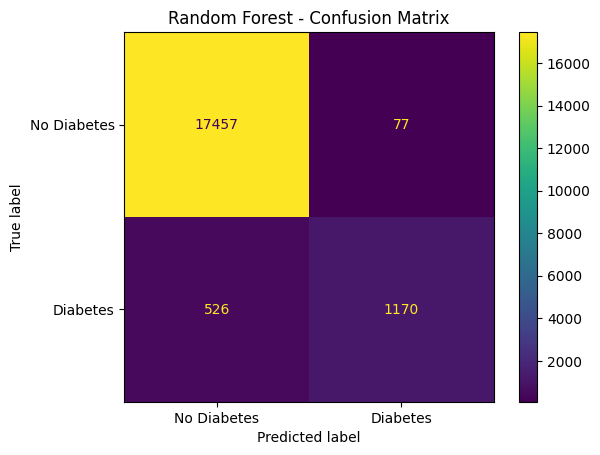

In [14]:
# Confusion matrix for the Random Forest model

cm = confusion_matrix(y_test, rf_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Diabetes", "Diabetes"]
)

disp.plot()
plt.title("Random Forest - Confusion Matrix")
plt.show()


## 12. ROC Curve

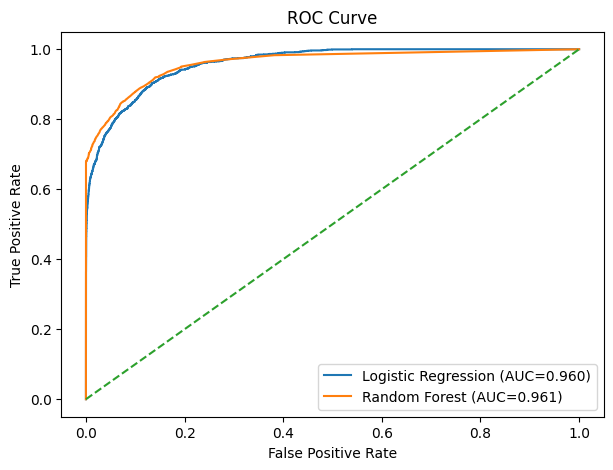

In [15]:
# Compare ROC curves of both models

logistic_fpr, logistic_tpr, _ = roc_curve(y_test, logistic_prob)
rf_fpr, rf_tpr, _ = roc_curve(y_test, rf_prob)

plt.figure(figsize=(7, 5))
plt.plot(logistic_fpr, logistic_tpr, label=f"Logistic Regression (AUC={logistic_results['ROC-AUC']:.3f})")
plt.plot(rf_fpr, rf_tpr, label=f"Random Forest (AUC={rf_results['ROC-AUC']:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()


## 13. Feature Importance - Random Forest

,Feature,Importance
4,num__HbA1c_level,0.346501
5,num__blood_glucose_level,0.264011
0,num__age,0.188661
3,num__bmi,0.129246
1,num__hypertension,0.025774
2,num__heart_disease,0.014433
9,cat__smoking_history_No Info,0.009913
12,cat__smoking_history_former,0.005349
13,cat__smoking_history_never,0.003362
7,cat__gender_Male,0.003092


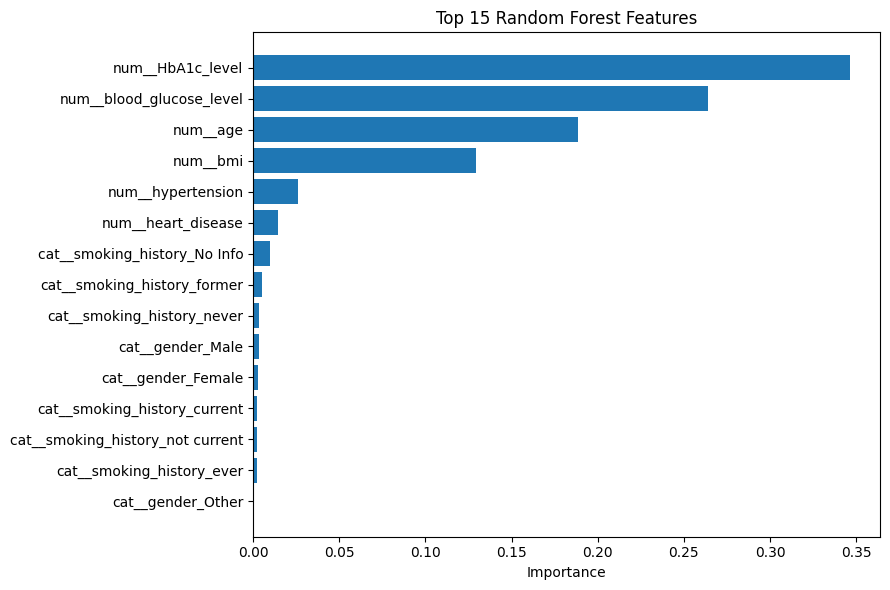

In [16]:
# Get transformed feature names from the fitted preprocessing pipeline

rf_preprocessor = random_forest_model.named_steps["preprocessor"]
rf_classifier = random_forest_model.named_steps["classifier"]

feature_names = rf_preprocessor.get_feature_names_out()
importances = rf_classifier.feature_importances_

feature_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
}).sort_values("Importance", ascending=False)

display(feature_importance_df.head(15))

plt.figure(figsize=(9, 6))
top_features = feature_importance_df.head(15).sort_values("Importance")
plt.barh(top_features["Feature"], top_features["Importance"])
plt.xlabel("Importance")
plt.title("Top 15 Random Forest Features")
plt.tight_layout()
plt.show()


## 14. Test a New Patient

In [17]:
# Example patient data
# Change these values to test another patient

new_patient = pd.DataFrame([{
    "gender": "Female",
    "age": 55,
    "hypertension": 1,
    "heart_disease": 0,
    "smoking_history": "never",
    "bmi": 30.5,
    "HbA1c_level": 6.2,
    "blood_glucose_level": 145
}])

prediction = random_forest_model.predict(new_patient)[0]
probability = random_forest_model.predict_proba(new_patient)[0, 1]

print("Predicted class:", prediction)
print(f"Probability of diabetes: {probability:.2%}")

if prediction == 1:
    print("Prediction: Diabetes")
else:
    print("Prediction: No Diabetes")


Predicted class: 0
Probability of diabetes: 2.00%
Prediction: No Diabetes


## 15. Save the Best Model

The model with the better evaluation result can be selected for saving. Here, F1 score is used for model selection because the dataset has an imbalanced target.

In [18]:
# Select the model with the better F1 score

if rf_results["F1 Score"] >= logistic_results["F1 Score"]:
    best_model = random_forest_model
    best_model_name = "Random Forest"
else:
    best_model = logistic_model
    best_model_name = "Logistic Regression"

print("Selected model:", best_model_name)

# Save the complete pipeline (preprocessing + model)
joblib.dump(best_model, "diabetes_prediction_model.pkl")

print("Model saved as: diabetes_prediction_model.pkl")


Selected model: Random Forest
Model saved as: diabetes_prediction_model.pkl


## 16. Load Saved Model and Predict

In [19]:
# Load the saved model

loaded_model = joblib.load("diabetes_prediction_model.pkl")

loaded_prediction = loaded_model.predict(new_patient)[0]
loaded_probability = loaded_model.predict_proba(new_patient)[0, 1]

print("Loaded model prediction:", loaded_prediction)
print(f"Loaded model probability of diabetes: {loaded_probability:.2%}")


Loaded model prediction: 0
Loaded model probability of diabetes: 2.00%


# Conclusion

- This is a **binary classification** problem.
- `diabetes` is the target variable.
- Categorical features are converted using **One-Hot Encoding**.
- Numeric features are imputed and standardized.
- Two classification models are trained:
  1. Logistic Regression
  2. Random Forest Classifier
- The models are evaluated using Accuracy, Precision, Recall, F1 Score and ROC-AUC.
- The better model based on F1 Score is saved as `diabetes_prediction_model.pkl`.

> **Important:** This project is for educational/modeling purposes only. A machine-learning prediction should not be treated as a medical diagnosis.
